This file contains our Scikit-learn unsupervised models, which can be compared to find the most effective model and to aid in writing the research manuscript. The Clean_and_EDA.py must be ran inside this file so that the models have access to the data. There is plots, other figures, and accuracy scores so we can compare and validate our models. Model 1 is the isolated forest model. Contributions by Brendan Daly.

In [19]:
# Load in libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import IsolationForest
from Clean_and_EDA import Robot_milking_data_renamed

Parsing: Robot Farm #1.xlsx
Parsing: Robot Farm #10.xlsx
Parsing: Robot Farm #102.xlsx
Parsing: Robot Farm #103.xlsx
Parsing: Robot Farm #104.xlsx
Parsing: Robot Farm #105.xlsx
Parsing: Robot Farm #106.xlsx
Parsing: Robot Farm #109.xlsx
Parsing: Robot Farm #11.xlsx
Parsing: Robot Farm #111.xlsx
Parsing: Robot Farm #112.xlsx
Parsing: Robot Farm #113.xlsx
Parsing: Robot Farm #115.xlsx
Parsing: Robot Farm #118.xlsx
Parsing: Robot Farm #12.xlsx
Parsing: Robot Farm #122.xlsx
Parsing: Robot Farm #123.xlsx
Parsing: Robot Farm #125.xlsx
Parsing: Robot Farm #128.xlsx
Parsing: Robot Farm #129.xlsx
Parsing: Robot Farm #130.xlsx
Parsing: Robot Farm #134.xlsx
Parsing: Robot Farm #137.xlsx
Parsing: Robot Farm #139.xlsx
Parsing: Robot Farm #14.xlsx
Parsing: Robot Farm #141.xlsx
Parsing: Robot Farm #143.xlsx
Parsing: Robot Farm #144.xlsx
Parsing: Robot Farm #145.xlsx
Parsing: Robot Farm #146.xlsx
Parsing: Robot Farm #147.xlsx
Parsing: Robot Farm #148.xlsx
Parsing: Robot Farm #15.xlsx
Parsing: Robot Fa

,Cow_ID,ELISA_SN,ELISA_Interpretation,ELISA_Classification,Test_Date
0,301,0.13,Positive,2,2025-05-22
1,123,0.48,Suspect,1,2025-05-22
2,92,0.85,Negative,0,2025-05-22
3,247,0.36,Positive,2,2025-05-22
4,1,0.73,Negative,0,2025-05-22
...,...,...,...,...,...
206,ORANGETAG,0.84,Negative,0,2025-05-22
207,7,0.39,Positive,2,2025-05-22
208,45,0.87,Negative,0,2025-05-22
209,7777,0.50,Negative,0,2025-05-22



##### POST-CLEAN #####
  Cow_ID  ELISA_SN ELISA_Interpretation  ELISA_Classification  Test_Date
0    301      0.13             Positive                     2 2025-05-22
1    123      0.48              Suspect                     1 2025-05-22
2     92      0.85             Negative                     0 2025-05-22
    Cow_ID  ELISA_SN ELISA_Interpretation  ELISA_Classification  Test_Date
208     45      0.87             Negative                     0 2025-05-22
209   7777      0.50             Negative                     0 2025-05-22
210   9999      0.58             Negative                     0 2025-05-22

Number of rows:
211

Unique values:
Cow_ID                  204
ELISA_SN                 91
ELISA_Interpretation      3
ELISA_Classification      3
Test_Date                 1
dtype: int64

Duplicates
Empty DataFrame
Columns: [Cow_ID, ELISA_SN, ELISA_Interpretation, ELISA_Classification, Test_Date]
Index: []

Number of duplicate rows: 0

##### POST-CLEAN #####

Number of files: 97

,day_production,fat_indication,protein_indication,milkings,refusals,failures,isk
day_production,1.00,-0.05,-0.03,0.41,0.12,-0.04,0.41
fat_indication,-0.05,1.00,0.00,-0.03,-0.01,-0.00,-0.03
protein_indication,-0.03,0.00,1.00,-0.04,-0.00,0.01,-0.02
milkings,0.41,-0.03,-0.04,1.00,0.35,-0.15,0.28
refusals,0.12,-0.01,-0.00,0.35,1.00,0.01,0.05
failures,-0.04,-0.00,0.01,-0.15,0.01,1.00,-0.07
isk,0.41,-0.03,-0.02,0.28,0.05,-0.07,1.00


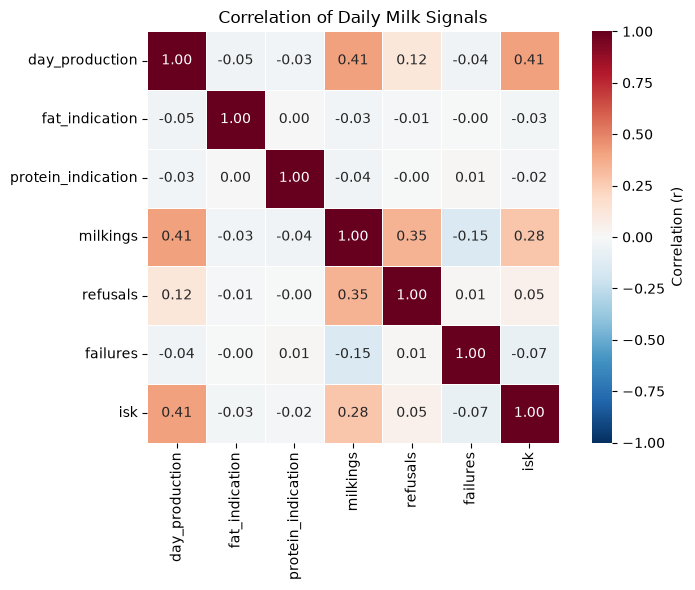

In [13]:
# Run the cleaning script once to obtain the data here for the models to use!
%run Clean_and_EDA.py

In [24]:
# Select features to use in the model
# List of all features, most features should not be used in each model
features_list = ['Date','Date Time','Lactation Days','Programmed Rest Feed','Rest Feed','Day Production','Day Production Dev','ISK','Milkings','Refusals','Failures','Milking Avg','Refusals Avg','Failures Avg','Fat Indication','Protein Indication','Lactose Indication','Address','Failure','Milk Yield','Milk Yield Expected','Conductivity LF','Conductivity RF','Conductivity LR','Conductivity RR','Color Code RF','Color Code LR','Color Code RR','Milk Temperature','Device Name','Visit Result','Milk Speed','Milk Speed Max','Milking Interval (min)','Box Time (min)','Treat Time (min)','Dead Milk Time LF (min)','Dead Milk Time RF (min)','Dead Milk Time LR (min)','Dead Milk Time RR (min)','Milk Time LF (min)','Milk Time RF (min)','Milk Time LR (min)','Milk Time RR (min)','Attachments LF','Attachments RF','Attachments LR','Attachments RR','Milk Destination','Routing Direction','Bottle Num','Lactation Number','Calving Date','Lactation Production','Predicted Production 305d','Milk Separated','Amount Total','Rest Feed Total','Fat %','Protein %','Lactose %','Event Type','Lactation Section','Lactation Day','Event Description']

# Isolated Forest Model Features
iso_forest_features = [
    'Lactation Days',
    'Day Production',
    'Day Production Dev',
    'Milkings',
    'Refusals',
    'Failures',
    'Milk Yield',
    'Milk Yield Expected',
    'Conductivity LF',
    'Conductivity RF',
    'Conductivity LR',
    'Conductivity RR',
    'Milk Temperature',
    'Milk Speed',
    'Milk Speed Max',
    'Milking Interval (min)',
    'Fat %',
    'Protein %',
    'Lactose %',
    'Lactation Number'
]


# Select Isolated Forest Model Features from Each Sheet
iso_forest_features_dict = {}

for file_name, tables in Robot_milking_data_renamed.items():
    iso_forest_features_dict[file_name] = {}

    for table_name, df in tables.items():
        missing = [
            feature for feature in iso_forest_features
            if feature not in df.columns
        ]

        if missing:
            print(f"{file_name} | {table_name}: missing {missing}")

        available = [
            feature for feature in iso_forest_features
            if feature in df.columns
        ]

        iso_forest_features_dict[file_name][table_name] = (
            df[available].copy()
        )

first_file = next(iter(iso_forest_features_dict))
first_table = next(iter(iso_forest_features_dict[first_file]))
df_features = iso_forest_features_dict[first_file][first_table]

# (Yikes, lets just clean the data fully this time...)
print(df_features.shape)
print(df_features.head())

Robot Farm #1.xlsx | daily_milk: missing ['Milk Yield', 'Milk Yield Expected', 'Conductivity LF', 'Conductivity RF', 'Conductivity LR', 'Conductivity RR', 'Milk Temperature', 'Milk Speed', 'Milk Speed Max', 'Milking Interval (min)', 'Fat %', 'Protein %', 'Lactose %', 'Lactation Number']
Robot Farm #1.xlsx | quality: missing ['Lactation Days', 'Day Production', 'Day Production Dev', 'Milkings', 'Refusals', 'Failures', 'Milk Speed', 'Milk Speed Max', 'Milking Interval (min)', 'Fat %', 'Protein %', 'Lactose %', 'Lactation Number']
Robot Farm #1.xlsx | visits: missing ['Lactation Days', 'Day Production', 'Day Production Dev', 'Milkings', 'Refusals', 'Failures', 'Conductivity LF', 'Conductivity RF', 'Conductivity LR', 'Conductivity RR', 'Fat %', 'Protein %', 'Lactose %', 'Lactation Number']
Robot Farm #1.xlsx | lactation: missing ['Day Production Dev', 'Milk Yield', 'Milk Yield Expected', 'Conductivity LF', 'Conductivity RF', 'Conductivity LR', 'Conductivity RR', 'Milk Temperature', 'Milk S

In [ ]:
# Parameters (Experiment with the model by changing these!)
n_estimators = 100 # number of trees
contamination = 0.01 # expected proportion of anomalies
sample_size = 256 # number of samples used to train each tree

In [ ]:
# Train Isolated Forest Model
iso_forest = IsolationForest(n_estimators=n_estimators,
                             contamination=contamination,
                             max_samples=sample_size,
                             random_state=123) # Reproducibility
iso_forest.fit(iso_forest_features)

In [ ]:
# Calculate anomaly scores and classify anomalies
Robot_milking_data_renamed = Robot_milking_data_renamed.loc[iso_forest_features.index].copy()
Robot_milking_data_renamed['anomaly_score'] = iso_forest.decision_function(iso_forest_features)
Robot_milking_data_renamed['anomaly'] = iso_forest.predict(iso_forest_features)
Robot_milking_data_renamed['anomaly'].value_counts()

In [ ]:
# Visualization of the results
plt.figure(figsize=(10, 5))

# Plot normal instances
normal = Robot_milking_data_renamed[Robot_milking_data_renamed['anomaly'] == 1]
plt.scatter(normal.index, normal['anomaly_score'], label='Normal')

# Plot anomalies
anomalies = Robot_milking_data_renamed[Robot_milking_data_renamed['anomaly'] == -1]
plt.scatter(anomalies.index, anomalies['anomaly_score'], label='Anomaly')
plt.xlabel("Instance")
plt.ylabel("Anomaly Score")
plt.legend()
plt.show()